In [1]:
!pip install peft accelerate rouge-score -q

  Preparing metadata (setup.py) ... done


In [ ]:
# Mount Google Drive to access data
from google.colab import drive
drive.mount('/content/drive')

import json
import random
import itertools
from collections import defaultdict
from PIL import Image
import torch
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = '/content/drive/MyDrive/derma_project'
DATA_DIR = f'{PROJECT_DIR}/data'

Mounted at /content/drive


In [ ]:
# Load dermatology report
with open(f'{DATA_DIR}/generated_reports_clean.json', 'r') as f:
    reports = json.load(f)

# Create evaluation sample using random sampling stratified by diagnosis
random.seed(42)
shuffled = reports.copy()
random.shuffle(shuffled)
split_idx = int(len(shuffled) * 0.9)    # Use 90% for training, 10% for validation
val_reports = shuffled[split_idx:]

# Group validation reports by diagnosis
val_reports_by_dx = defaultdict(list)
for r in val_reports:
    val_reports_by_dx[r['diagnosis']].append(r)

# Sample up to 13 examples per diagnosis for evaluation
eval_sample = []
for dx, examples in val_reports_by_dx.items():
    n = min(13, len(examples))
    sampled = random.sample(examples, n)
    eval_sample.append(sampled)

# Flatten the list of lists into a single list of examples
eval_sample = list(itertools.chain.from_iterable(eval_sample))
print(f"eval_sample rebuilt: {len(eval_sample)} examples")

eval_sample rebuilt: 91 examples


In [ ]:
from peft import PeftModel
from transformers import MllamaForConditionalGeneration, AutoProcessor

SAVE_PATH = f'{PROJECT_DIR}/checkpoints/final_model'
MODEL_ID = "meta-llama/Llama-3.2-11B-Vision-Instruct"

# Load the base model with the same configuration as used for fine-tuning
base_model = MllamaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager"
)

# Load the processor for the model
processor = AutoProcessor.from_pretrained(MODEL_ID, use_fast=False)
model = PeftModel.from_pretrained(base_model, SAVE_PATH)
model.eval()

print(f"Model loaded")
print(f"Memory: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/906 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

...

tokenizer_config.json: 0.00B [00:00, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

Model loaded
Memory: 21.4 GB


In [ ]:
# Test the model with a sample image and prompt
test_example = next(r for r in eval_sample if r['diagnosis'] == 'mel')
image = Image.open(test_example['image_path']).convert("RGB")

prompt = "Describe this image."

# Tokenize the prompt and check token ids against the model's vocabulary size
text_inputs = processor.tokenizer(prompt, return_tensors="pt")
input_ids = text_inputs['input_ids']

print(f"Vocab size: {model.config.text_config.vocab_size}")
print(f"Max token id in prompt: {input_ids.max().item()}")
print(f"Input ids shape: {input_ids.shape}")
print(f"Any out of range: {(input_ids >= model.config.text_config.vocab_size).any()}")

Vocab size: 128256
Max token id in prompt: 128000
Input ids shape: torch.Size([1, 5])
Any out of range: False


In [ ]:
# Validate image preprocessing
image = Image.open(test_example['image_path']).convert("RGB")

# Process the image and prompt together, checking the outputs
image_inputs = processor.image_processor(image, return_tensors="pt")
text_inputs = processor.tokenizer("Describe this image.", return_tensors="pt")

print(f"pixel_values shape: {image_inputs['pixel_values'].shape}")
print(f"pixel_values dtype: {image_inputs['pixel_values'].dtype}")
print(f"pixel_values min: {image_inputs['pixel_values'].min():.3f}")
print(f"pixel_values max: {image_inputs['pixel_values'].max():.3f}")

# Check for aspect ratio inputs if they exist
if 'aspect_ratio_ids' in image_inputs:
    print(f"aspect_ratio_ids: {image_inputs['aspect_ratio_ids']}")
    print(f"aspect_ratio_ids max: {image_inputs['aspect_ratio_ids'].max().item()}")

# Prepare inputs for the model, ensuring all tensors are on the correct device
input_ids = text_inputs['input_ids'].to(model.device)
labels = input_ids.clone()
labels[:, :-2] = -100

# Prepare the inputs dictionary, including optional aspect ratio inputs if they exist
inputs = {
    'input_ids': input_ids,
    'attention_mask': text_inputs['attention_mask'].to(model.device),
    'pixel_values': image_inputs['pixel_values'].to(model.device),
    'labels': labels,
}
if 'aspect_ratio_ids' in image_inputs:
    inputs['aspect_ratio_ids'] = image_inputs['aspect_ratio_ids'].to(model.device)
if 'aspect_ratio_mask' in image_inputs:
    inputs['aspect_ratio_mask'] = image_inputs['aspect_ratio_mask'].to(model.device)

print("\nAttempting forward pass...")
try:
    with torch.no_grad():
        outputs = model(**inputs)
    print(f"Success! Loss: {outputs.loss.item():.4f}")
except Exception as e:
    print(f"Failed: {e}")

pixel_values shape: torch.Size([1, 1, 4, 3, 560, 560])
pixel_values dtype: torch.float32
pixel_values min: -1.792
pixel_values max: 1.264
aspect_ratio_ids: tensor([[2]])
aspect_ratio_ids max: 2

Attempting forward pass...
Success! Loss: 6.9317


In [ ]:
# Define the occlusion heatmap function
def occlusion_heatmap(model, processor, image_path, age, sex, localization,
                      grid_size=7, save_path=None):

    image = Image.open(image_path).convert("RGB")
    w, h = image.size

    prompt = f"""<|begin_of_text|><|start_header_id|>user<|end_header_id|>

<|image|>You are a dermatology assistant analyzing a dermatoscopic image.

Patient information:
- Age: {age} years old
- Sex: {sex}
- Lesion location: {localization}

Analyze the visual features of this lesion and produce a structured clinical report.<|eot_id|><|start_header_id|>assistant<|end_header_id|>

"""
    # Define a helper function to compute the loss for a given image input
    def get_loss(img):
        image_inputs = processor.image_processor(img, return_tensors="pt")
        text_inputs = processor.tokenizer(prompt, return_tensors="pt")

        input_ids = text_inputs['input_ids'].to(model.device)


        labels = input_ids.clone()
        labels[:, :-10] = -100

        inputs = {
            'input_ids': input_ids,
            'attention_mask': text_inputs['attention_mask'].to(model.device),
            'pixel_values': image_inputs['pixel_values'].to(model.device),
            'labels': labels,
        }
        if 'aspect_ratio_ids' in image_inputs:
            inputs['aspect_ratio_ids'] = image_inputs['aspect_ratio_ids'].to(model.device)
        if 'aspect_ratio_mask' in image_inputs:
            inputs['aspect_ratio_mask'] = image_inputs['aspect_ratio_mask'].to(model.device)

        with torch.no_grad():
            outputs = model(**inputs)
        return outputs.loss.item()
    
    # Compute the baseline loss with the original image
    baseline_loss = get_loss(image)
    print(f"Baseline loss: {baseline_loss:.4f}")

    # Create occlusion grid and compute importance scores
    patch_w = w // grid_size
    patch_h = h // grid_size
    importance = np.zeros((grid_size, grid_size))

    # Iterate over each patch, occlude it, and compute the loss difference
    total_patches = grid_size * grid_size
    for i in range(grid_size):
        for j in range(grid_size):
            patch_num = i * grid_size + j + 1
            print(f"Patch {patch_num}/{total_patches}", end='\r')

            img_occluded = image.copy()
            pixels = img_occluded.load()
            for pi in range(i * patch_h, min((i+1) * patch_h, h)):
                for pj in range(j * patch_w, min((j+1) * patch_w, w)):
                    pixels[pj, pi] = (128, 128, 128)

            occluded_loss = get_loss(img_occluded)
            importance[i, j] = occluded_loss - baseline_loss

    print(f"\nOcclusion complete")

    # Normalize importance scores to [0, 1] for visualization
    importance = (importance - importance.min()) / (importance.max() - importance.min() + 1e-8)

    # Initialize the figure and axes for visualization
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(image)
    axes[0].set_title('Original lesion image')
    axes[0].axis('off')

    axes[1].imshow(importance, cmap='hot', interpolation='bilinear')
    axes[1].set_title('Importance map\n(bright = high attention)')
    axes[1].axis('off')

    axes[2].imshow(image)
    axes[2].imshow(importance, cmap='hot', alpha=0.5,
                   interpolation='bilinear',
                   extent=[0, w, h, 0])
    axes[2].set_title('Importance overlay')
    axes[2].axis('off')

    plt.suptitle(f'Occlusion map — {age}yo {sex}, {localization}', fontsize=12)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")

    plt.show()
    return importance

print("occlusion_heatmap defined")

occlusion_heatmap defined


Testing on: ISIC_0032841
Patient: 60yo female, chest
Baseline loss: 2.5413

Occlusion complete
Saved to /content/drive/MyDrive/derma_project/data/occlusion_mel.png


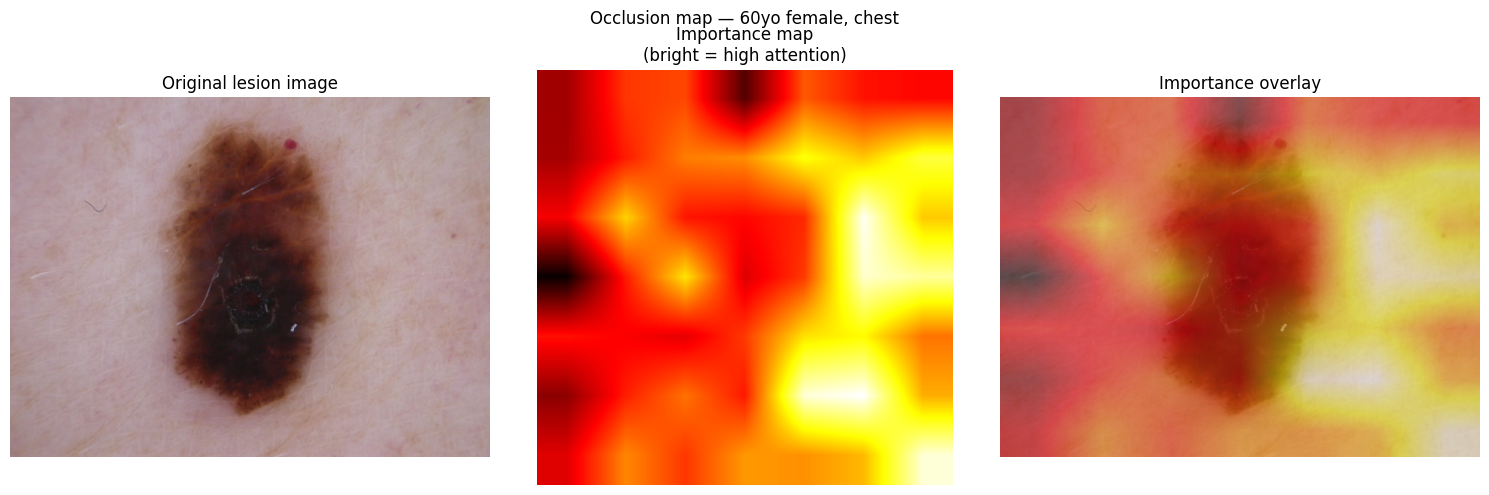

In [ ]:
# Test the occlusion heatmap function on a melanoma sample image
mel_example = next(r for r in eval_sample if r['diagnosis'] == 'mel')

print(f"Testing on: {mel_example['image_id']}")
print(f"Patient: {mel_example['age']}yo {mel_example['sex']}, {mel_example['localization']}")

importance = occlusion_heatmap(
    model, processor,
    mel_example['image_path'],
    mel_example['age'],
    mel_example['sex'],
    mel_example['localization'],
    grid_size=7,
    save_path=f"{PROJECT_DIR}/data/occlusion_mel.png"
)

BCC: ISIC_0028671 — 55yo male, back
Baseline loss: 2.4487

Occlusion complete
Saved to /content/drive/MyDrive/derma_project/data/occlusion_bcc.png


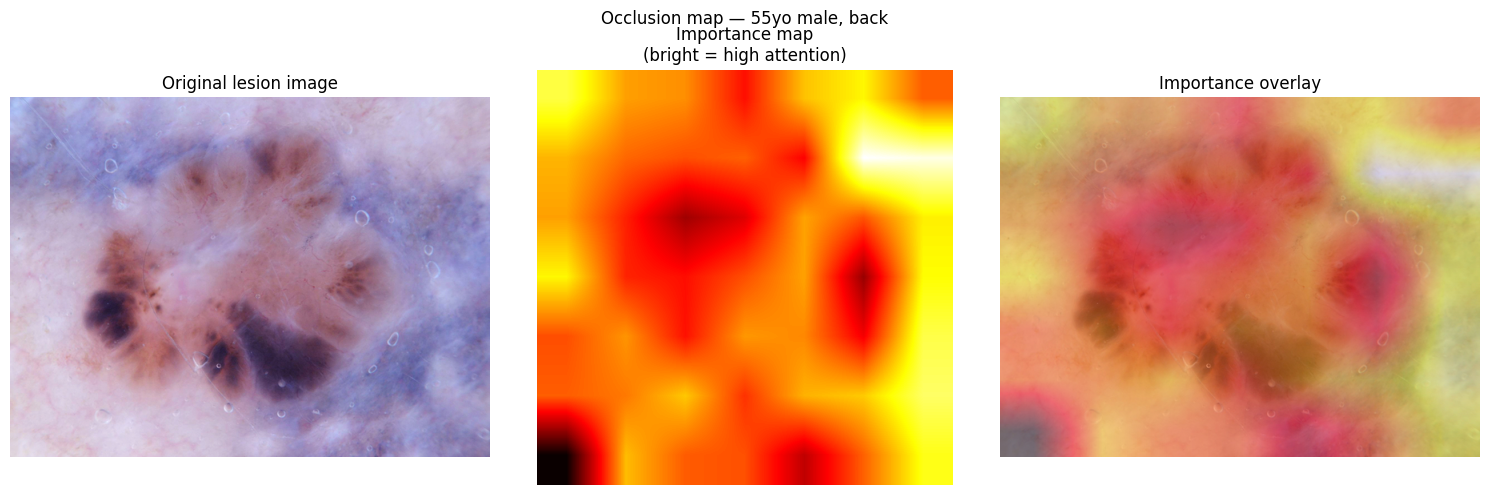

In [ ]:
# Test the occlusion heatmap function on a BCC sample image
bcc_example = next(r for r in eval_sample if r['diagnosis'] == 'bcc')
print(f"BCC: {bcc_example['image_id']} — {bcc_example['age']}yo {bcc_example['sex']}, {bcc_example['localization']}")

importance_bcc = occlusion_heatmap(
    model, processor,
    bcc_example['image_path'],
    bcc_example['age'],
    bcc_example['sex'],
    bcc_example['localization'],
    grid_size=7,
    save_path=f"{PROJECT_DIR}/data/occlusion_bcc.png"
)

NV: ISIC_0029861 — 35yo female, back
Baseline loss: 2.3551

Occlusion complete
Saved to /content/drive/MyDrive/derma_project/data/occlusion_nv.png


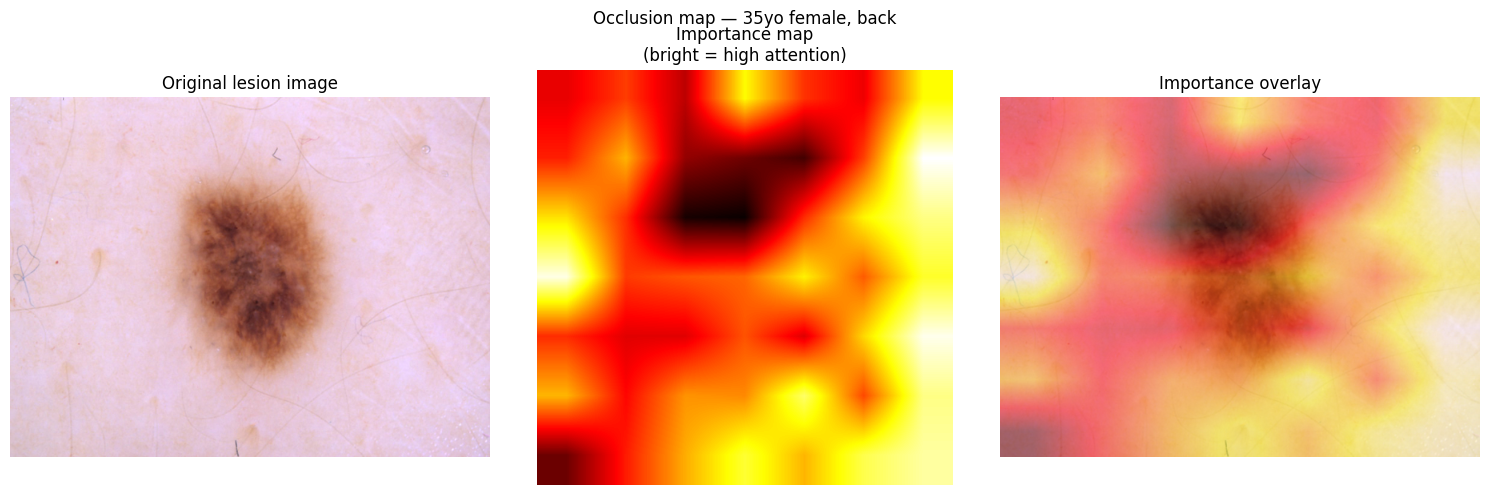

In [ ]:
# Test the occlusion heatmap function on a NV sample image
nv_example = next(r for r in eval_sample if r['diagnosis'] == 'nv')
print(f"NV: {nv_example['image_id']} — {nv_example['age']}yo {nv_example['sex']}, {nv_example['localization']}")

importance_nv = occlusion_heatmap(
    model, processor,
    nv_example['image_path'],
    nv_example['age'],
    nv_example['sex'],
    nv_example['localization'],
    grid_size=7,
    save_path=f"{PROJECT_DIR}/data/occlusion_nv.png"
)